<center>
<img src="img/logo-hds.png" width="650"/>

***

<center>Lecture 9</center>

***

<center>Model Evaluation</center>

<center>Confusion Matrix + ROC Curve + Leakage-Aware Splits</center>

***

<center>9 November 2026</center>
<center>Rahman Peimankar</center>

## From Lecture 8 to Lecture 9

Lecture 8:

```text
clean / noisy ECG windows
        ↓
simple signal features
        ↓
Logistic Regression / Decision Tree
        ↓
predictions
```

Today:

```text
predictions
        ↓
is the evaluation trustworthy?
        ↓
confusion matrix
        ↓
thresholds
        ↓
ROC curve / AUC
```

The model is only useful if the evaluation is scientifically valid.

## Learning outcomes

By the end of today you should be able to:

1. explain why window-level random splitting can cause leakage;
2. keep related ECG windows together during train/test splitting;
3. interpret a binary confusion matrix;
4. calculate Accuracy, Sensitivity and Specificity;
5. explain how the classification threshold changes predictions;
6. explain the ROC curve using Sensitivity and False Positive Rate;
7. interpret ROC-AUC at an introductory level;
8. recognize what this dataset can and cannot tell us about bias/fairness.

## We keep the same dataset

As in Lectures 7 and 8:

### Clean ECG
- MIT-BIH `118`
- MIT-BIH `119`

### Noisy ECG
- NSTDB `118e12`
- NSTDB `119e12`

Target:

```text
0 = clean
1 = noisy
```

Each recording is divided into **10-second windows**.


## Setup

In [1]:
# Run once if needed:
# %pip install wfdb numpy pandas matplotlib scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

plt.rcParams["figure.figsize"] = (12, 4)

## Rebuild the Lecture 8 feature table

We keep the same simple features:

- standard deviation;
- amplitude range;
- mean absolute change;
- derivative RMS;
- mean absolute amplitude.

One row still represents **one 10-second ECG window**.

In [3]:
def window_features(x, fs, record_id, group_id, label, window_s=10):
    n = int(window_s * fs)
    rows = []

    for start in range(0, len(x) - n + 1, n):
        w = x[start:start + n]
        dx = np.diff(w)

        rows.append({
            "record_id": record_id,
            "group_id": group_id,
            "start_s": start / fs,
            "std": np.std(w),
            "amplitude_range": np.ptp(w),
            "mean_abs_change": np.mean(np.abs(dx)),
            "derivative_rms": np.sqrt(np.mean(dx**2)),
            "mean_abs_amplitude": np.mean(np.abs(w)),
            "label": label
        })

    return rows

## Preserve the underlying-record group

The noisy records are derived from the corresponding clean ECG records:

```text
118    + 118e12  → group 118

119    + 119e12  → group 119
```

This means windows from the same underlying ECG should stay together during a leakage-aware split.

In [4]:
start_s = 305
duration_s = 120

pairs = [("118", "118e12"), ("119", "119e12")]
rows = []

for clean_name, noisy_name in pairs:
    header = wfdb.rdheader(clean_name, pn_dir="mitdb")
    fs = header.fs

    sampfrom = int(start_s * fs)
    sampto = int((start_s + duration_s) * fs)

    clean = wfdb.rdrecord(clean_name, pn_dir="mitdb", sampfrom=sampfrom, sampto=sampto, channels=[0])
    noisy = wfdb.rdrecord(noisy_name, pn_dir="nstdb", sampfrom=sampfrom, sampto=sampto, channels=[0])

    rows += window_features(clean.p_signal[:, 0], fs, record_id=clean_name, group_id=clean_name, label=0)
    rows += window_features(noisy.p_signal[:, 0], fs, record_id=noisy_name, group_id=clean_name, label=1)

feature_table = pd.DataFrame(rows)
feature_table[["record_id", "group_id", "start_s", "label"]].head()

,record_id,group_id,start_s,label
0,118,118,0.0,0
1,118,118,10.0,0
2,118,118,20.0,0
3,118,118,30.0,0
4,118,118,40.0,0


## Define features, target and groups

```text
X      → signal features

y      → clean / noisy label

groups → underlying ECG record
```

The `groups` variable is what protects related windows from being split across train and test.

In [5]:
feature_names = [
    "std",
    "amplitude_range",
    "mean_abs_change",
    "derivative_rms",
    "mean_abs_amplitude"
]

X = feature_table[feature_names]
y = feature_table["label"]
groups = feature_table["group_id"]

print("Rows:", len(X))
print("Groups:", groups.unique())
print()
print(y.value_counts())

Rows: 48
Groups: ['118' '119']

label
0    24
1    24
Name: count, dtype: int64


## Row-wise random split

This is what we did in Lecture 8:

```python
train_test_split(...)
```

It treats every 10-second window as if it were independent.

But windows from the same underlying ECG can appear in **both** training and test sets.

In [6]:
X_train_r, X_test_r, y_train_r, y_test_r, groups_train_r, groups_test_r = train_test_split(X, y, groups, test_size=0.25, random_state=42, stratify=y)

overlap = set(groups_train_r).intersection(set(groups_test_r))

print("Groups in training:", sorted(set(groups_train_r)))
print("Groups in test:", sorted(set(groups_test_r)))
print("Group overlap:", overlap)

Groups in training: ['118', '119']
Groups in test: ['118', '119']
Group overlap: {'118', '119'}


## Why is that leakage?

Imagine:

```text
Record 118
 ├─ window 1  → training
 ├─ window 2  → training
 ├─ window 3  → test
 └─ window 4  → test
```

The test set contains new **windows**, but not a new underlying ECG.

The model may benefit from record-specific characteristics already seen during training.

For health data:

> **window-wise independence is not the same as subject/record-wise independence.**

## Group-wise split

Now all windows from one underlying record remain together.

With only two record groups in this teaching example:

```text
one group → training

one group → test
```

This is intentionally simple and demonstrates the principle clearly.

In [7]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)

train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train_g = X.iloc[train_idx]
X_test_g = X.iloc[test_idx]

y_train_g = y.iloc[train_idx]
y_test_g = y.iloc[test_idx]

groups_train_g = groups.iloc[train_idx]
groups_test_g = groups.iloc[test_idx]

print("Training group:", groups_train_g.unique())
print("Test group:", groups_test_g.unique())
print("Group overlap:", set(groups_train_g).intersection(set(groups_test_g)))

Training group: ['118']
Test group: ['119']
Group overlap: set()


## What question does each split answer?

### Row-wise split

> Can the model classify another window when related windows may already have been seen?

### Group-wise split

> Can the model generalize to windows from a different underlying ECG record?

For real projects, the grouping variable may be:

```text
patient_id
record_id
hospital/site
device
```

depending on the scientific question.

## Fit the same Logistic Regression model

The algorithm stays the same.

Only the **evaluation design** changes.

In [8]:
def make_model():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ])

model_row = make_model()
model_group = make_model()

model_row.fit(X_train_r, y_train_r)
model_group.fit(X_train_g, y_train_g)

prob_row = model_row.predict_proba(X_test_r)[:, 1]
prob_group = model_group.predict_proba(X_test_g)[:, 1]

pred_row = (prob_row >= 0.50).astype(int)
pred_group = (prob_group >= 0.50).astype(int)

## Other common forms of leakage

### Participant / record leakage
Related samples appear in train and test.

### Preprocessing leakage
Scaling or imputation is fitted before the split.

### Feature-selection leakage
Features are selected using labels from the full dataset.

### Temporal leakage
Future information is used to predict an earlier event.

### Target leakage
A feature directly or indirectly contains the answer.

##### A good test set should imitate the information available at real prediction time.

## Binary confusion matrix

<div>
<center>
<img src="img/confusion_matrix.png" width="700"/>
</center>
</div>

A confusion matrix compares:

```text
actual class
vs
predicted class
```

The four possible outcomes are:

```text
TP   TN   FP   FN
```

**Note:** Some diagrams transpose the axes. Always read the axis labels.

## True / false and positive / negative

<div>
<center>
<table><tr>
<td><img src="img/confusion_rows.png" width="440"/></td>
<td><img src="img/confusion_columns.png" width="440"/></td>
</tr></table>
</center>
</div>


```text
positive = noisy ECG
negative = clean ECG
```

Therefore:

- **TP**: noisy correctly classified as noisy
- **TN**: clean correctly classified as clean
- **FP**: clean incorrectly classified as noisy
- **FN**: noisy incorrectly classified as clean

## Three useful metrics from the confusion matrix

### Accuracy

$Accuracy = \frac{TP + TN}{TP + TN + FP + FN}$

### Sensitivity

$Sensitivity = \frac{TP}{TP + FN}$


For us:

> Of all truly noisy windows, how many were detected?

### Specificity

$Specificity = \frac{TN}{TN + FP}$

For us:

> Of all truly clean windows, how many were correctly rejected as non-noisy?

## Calculate the binary metrics

In [9]:
def evaluate_at_threshold(y_true, probability, threshold=0.50):
    pred = (probability >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, pred),
        "sensitivity": sensitivity,
        "specificity": specificity,
        "false_positive_rate": 1 - specificity,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn
    }

## Confusion matrix for the group-wise test set

scikit-learn places:

```text
actual labels    → rows

predicted labels → columns
```

So always check the orientation before interpreting TP, TN, FP and FN.

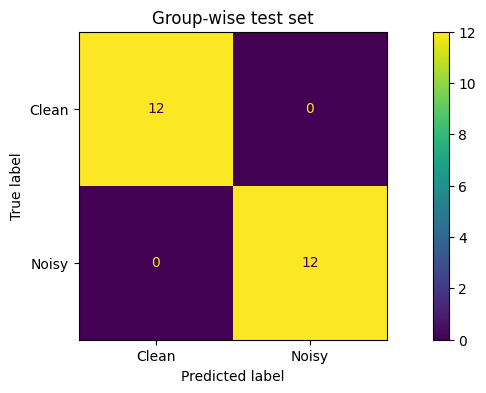

,threshold,accuracy,sensitivity,specificity,false_positive_rate,TP,TN,FP,FN
0,0.5,1.0,1.0,1.0,0.0,12,12,0,0


In [10]:
ConfusionMatrixDisplay.from_predictions(y_test_g, pred_group, display_labels=["Clean", "Noisy"])

plt.title("Group-wise test set")
plt.show()

pd.DataFrame([evaluate_at_threshold(y_test_g, prob_group, threshold=0.50)]).round(3)

## Probability becomes a class through a threshold

<div>
<center>
<img src="img/threshold_05.png" width="610"/>
</center>
</div>

A common rule is:

```text
P(noisy) ≥ 0.50 → noisy

P(noisy) < 0.50 → clean
```

But **0.50 is only one possible threshold**.

Changing it changes the confusion matrix.

## Threshold trade-off

Lower threshold:

```text
more windows predicted noisy
→ Sensitivity usually increases
→ False Positive Rate usually increases
```

Higher threshold:

```text
fewer windows predicted noisy
→ Sensitivity usually decreases
→ False Positive Rate usually decreases
```

ROC analysis summarizes this behaviour across many thresholds.

In [11]:
thresholds = [0.30, 0.50, 0.70, 0.9]

threshold_table = pd.DataFrame([
    evaluate_at_threshold(y_test_g, prob_group, threshold=t)
    for t in thresholds
])

threshold_table.round(3)

,threshold,accuracy,sensitivity,specificity,false_positive_rate,TP,TN,FP,FN
0,0.3,0.958,1.000,0.917,0.083,12,11,1,0
1,0.5,1.000,1.000,1.000,0.000,12,12,0,0
2,0.7,1.000,1.000,1.000,0.000,12,12,0,0
3,0.9,0.917,0.833,1.000,0.000,10,12,0,2


## ROC curve: the two axes

<div>
<center>
<img src="img/roc_axes.jpg" width="500"/>
</center>
</div>

The ROC curve plots:

```text
y-axis: True Positive Rate
        = Sensitivity

x-axis: False Positive Rate
        = 1 - Specificity
```

Each point corresponds to a **different classification threshold**.

## ROC curve = many thresholds

<div>
<center>
<img src="img/roc_points.jpg" width="520"/>
</center>
</div>

As the threshold moves, we obtain different:

```text
Sensitivity / False Positive Rate
```

pairs.

Connecting those operating points gives the ROC curve.

The ROC curve therefore evaluates the model's **ranking behaviour**, not just one threshold.

## ROC curve for our clean/noisy classifier

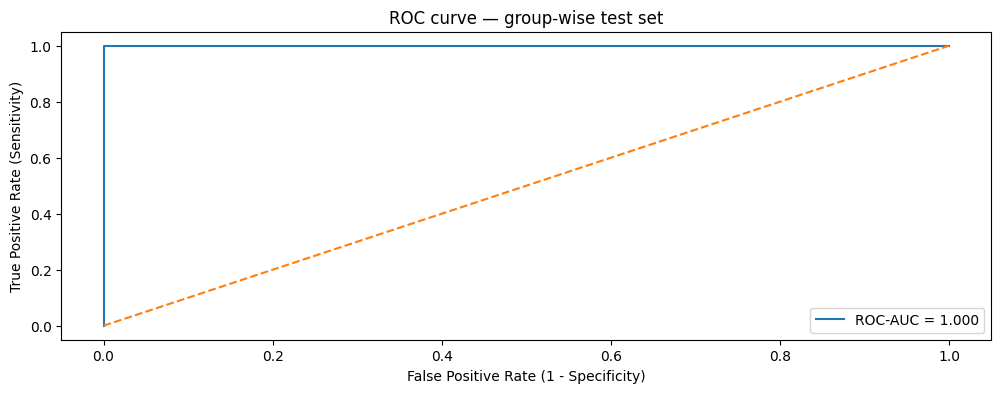

In [12]:
fpr_group, tpr_group, thresholds_group = roc_curve(y_test_g, prob_group)

auc_group = roc_auc_score(y_test_g, prob_group)

plt.plot(fpr_group, tpr_group, label=f"ROC-AUC = {auc_group:.3f}")
plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC curve — group-wise test set")
plt.legend()
plt.show()

## What does ROC-AUC mean?

ROC-AUC summarizes the ROC curve into one number.

Intuitively:

> How well does the model rank a randomly chosen noisy window above a randomly chosen clean window?

Typical interpretation:

```text
0.50 → no useful ranking

1.00 → perfect ranking
```

AUC does **not** tell us which threshold should be used in practice.

## Bias and fairness: what can this dataset tell us?

Our clean/noisy example is useful for:

- leakage;
- record-wise generalization;
- confusion matrices;
- ROC curves.

But it does **not** contain the demographic or clinical subgroup information needed for a meaningful fairness study.

So we should **not** claim fairness from this example.

In a real health project, subgroup evaluation may involve:

```text
age
sex
site
device
hospital
population group
```


The lesson is:

> evaluation should match the population where the model will be used.

## Exercise 1 — Threshold and confusion matrix (25 min)

Use the **group-wise** test probabilities.

### Tasks

1. evaluate thresholds:
   - `0.40`
   - `0.60`
2. for each threshold report:
   - Accuracy
   - Sensitivity
   - Specificity
3. create the confusion matrix for threshold `0.60`;
4. answer:

> Which error type increases when the threshold becomes higher?

### Starter code

In [13]:
# TODO:
# Evaluate threshold 0.40.

# TODO:
# Evaluate threshold 0.60.

# TODO:
# Put the results into one DataFrame.

# TODO:
# Create predictions using threshold 0.60.

# TODO:
# Plot the confusion matrix.

## Exercise 2 — ROC and leakage-aware evaluation (30 min)

### Part A

For the row-wise and group-wise test sets:

1. calculate ROC-AUC;
2. plot both ROC curves on the same figure.

### Part B

Answer briefly:

1. Why does the group-wise split represent a harder generalization problem?
2. Why should you always report the split strategy together with ROC-AUC?
3. What grouping variable should your semester project use?

### Starter code

In [14]:
# TODO:
# Calculate fpr/tpr for row-wise probabilities.

# TODO:
# Calculate fpr/tpr for group-wise probabilities.

# TODO:
# Calculate the two ROC-AUC values.

# TODO:
# Plot both ROC curves on the same figure.

## Project connection + take-home checklist

For your semester project, define:

- **positive class:**  
- **one row represents:**  
- **grouping variable:**  
- **train/test split strategy:**  
- **confusion-matrix metrics:**  
- **ROC-AUC:** yes / no  
- **one possible leakage risk:**  

Before trusting a score, ask:

- Are related samples separated correctly?
- What do TP, TN, FP and FN mean clinically?
- Is the threshold appropriate?
- Does ROC-AUC come from a truly unseen test set?
- Does the evaluation match the intended deployment population?
